# LSTM vs TCN vs ModernTCN - 심전도(ECG) 이상 탐지 (Anomaly Detection)

본 실습 노트북은 앞서 진행한 **ECG5000 (PhysioNet BIDMC 울혈성 심부전 환자 심박 데이터)** 데이터셋과 동일한 전처리 및 학습/검증/테스트 파이프라인을 기반으로, 시계열 딥러닝의 대표적인 세 가지 아키텍처인 **LSTM**, **TCN (Temporal Convolutional Network)**, **ModernTCN**을 각각 구현하고 성능을 비교·시각화하는 강좌용 예제입니다.

### 📋 실습 목차
1. **환경 설정 및 라이브러리 임포트**
2. **공개 심전도(ECG5000) 데이터셋 로드 및 분할 (Train / Validation / Test)**
3. **PyTorch Dataset 및 DataLoader 구성**
4. **3가지 신경망 아키텍처 정의 (LSTM / TCN / ModernTCN)**
5. **모델별 학습 (Train) 및 검증 (Validation)**
6. **테스트 평가 (Test) 및 아키텍처별 종합 결과 비교 시각화**

## 1. 환경 설정 및 라이브러리 임포트
실습에 필요한 PyTorch, NumPy, Matplotlib, Scikit-learn 라이브러리를 불러오고 시드를 고정합니다.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils import weight_norm
from torch.utils.data import Dataset, DataLoader

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, auc, accuracy_score, f1_score
)

# 재현성을 위한 시드 고정
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 중인 디바이스: {device}')

사용 중인 디바이스: cpu


## 2. 공개 심전도(ECG5000) 데이터 로드 및 분할 (Train / Validation / Test)
이전 트랜스포머 예제와 **100% 동일한 데이터셋 및 분할/정규화 로직**을 사용합니다.
- **정상 심박(Class 1)** $\rightarrow$ `0 (Normal)`
- **이상 심박(Class 2~5)** $\rightarrow$ `1 (Anomaly)`

In [2]:
print('ECG5000 데이터셋 다운로드 중...')
ecg = fetch_openml(name='ECG5000', version=1, as_frame=False, parser='auto')

raw_data = ecg.data.astype(np.float32)  # Shape: (5000, 140)
raw_target = ecg.target.astype(int)     # 1: Normal, 2~5: Anomaly

# Normal(1) -> 0, Anomaly(2,3,4,5) -> 1 로 이진 라벨 매핑
y = np.where(raw_target == 1, 0, 1).astype(np.int64)

# Train (70%), Validation (15%), Test (15%) 계층적 분할 (Stratified Split)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    raw_data, y, test_size=0.3, stratify=y, random_state=SEED
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED
)

# 데이터 정규화 (Train 데이터 기준으로 StandardScaler 피팅 후 변환)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

# 입력 형태: (Batch, Seq_Len=140, Feature_Dim=1)
X_train = X_train_scaled[..., np.newaxis]
X_val = X_val_scaled[..., np.newaxis]
X_test = X_test_scaled[..., np.newaxis]

print(f'Train 데이터 형태: {X_train.shape} | 이상 심박 비율: {y_train.mean():.2%}')
print(f'Validation 데이터 형태: {X_val.shape} | 이상 심박 비율: {y_val.mean():.2%}')
print(f'Test 데이터 형태: {X_test.shape} | 이상 심박 비율: {y_test.mean():.2%}')

ECG5000 데이터셋 다운로드 중...
Train 데이터 형태: (3498, 140, 1) | 이상 심박 비율: 41.60%
Validation 데이터 형태: (750, 140, 1) | 이상 심박 비율: 41.60%
Test 데이터 형태: (750, 140, 1) | 이상 심박 비율: 41.60%


## 3. PyTorch Dataset 및 DataLoader 구성

In [3]:
class ECGDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64
train_loader = DataLoader(ECGDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(ECGDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(ECGDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

## 4. 3가지 시계열 신경망 아키텍처 정의 (LSTM / TCN / ModernTCN)

동일한 입력 텐서 `(Batch, Seq_Len=140, Feature_Dim=1)`을 받아 정상(`0`) / 이상(`1`) 로짓을 출력하도록 3가지 모델을 설계합니다.

1. **LSTM (`ECGLSTMClassifier`)**: 순환 신경망(RNN)의 장기 의존성 게이트(Forget, Input, Output Gate)를 통해 순차적으로 심박 파형을 인코딩합니다.
2. **TCN (`ECGTCNClassifier`)**: Bai et al. (2018) 구조에 기반하여 **Causal Convolution(인과적 합성곱)**, **Dilated Convolution(팽창 합성곱)**, **Residual Connection(잔차 연결)**을 결합해 지수적으로 수용 영역(Receptive Field)을 넓힙니다.
3. **ModernTCN (`ECGModernTCNClassifier`)**: Luo & Wang (ICLR 2024) 구조에 기반하여 시계열을 **Patchify(스탬프 임베딩)**한 뒤, **큰 커널의 Depthwise 1D Convolution(시간 축 문맥 혼합)**과 **Pointwise ConvFFN(특징 차원 비선형 변환)**을 분리(Decoupling)하여 트랜스포머 수준의 전역 수용 영역과 합성곱의 효율성을 동시에 달성합니다.

In [4]:
# =====================================================================
# [모델 1] LSTM (Long Short-Term Memory) Classifier
# =====================================================================
class ECGLSTMClassifier(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=64, num_layers=2, dropout=0.1, num_classes=2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_dim * 2),
            nn.Linear(hidden_dim * 2, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        # x: (B, 140, 1)
        out, _ = self.lstm(x)       # out: (B, 140, hidden_dim * 2)
        feat = out.mean(dim=1)      # Global Average Pooling: (B, hidden_dim * 2)
        return self.classifier(feat)


# =====================================================================
# [모델 2] TCN (Temporal Convolutional Network) Classifier
# =====================================================================
class Chomp1d(nn.Module):
    """Causal Convolution을 위해 미래 시점 방향의 오른쪽 패딩을 잘라내는 모듈"""
    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):
        return x[:, :, :-self.chomp_size].contiguous()

class TemporalBlock(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, stride, dilation, padding, dropout=0.1):
        super().__init__()
        self.conv1 = weight_norm(nn.Conv1d(n_inputs, n_outputs, kernel_size,
                                           stride=stride, padding=padding, dilation=dilation))
        self.chomp1 = Chomp1d(padding)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout)

        self.conv2 = weight_norm(nn.Conv1d(n_outputs, n_outputs, kernel_size,
                                           stride=stride, padding=padding, dilation=dilation))
        self.chomp2 = Chomp1d(padding)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout)

        self.net = nn.Sequential(
            self.conv1, self.chomp1, self.relu1, self.dropout1,
            self.conv2, self.chomp2, self.relu2, self.dropout2
        )
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.net(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)

class ECGTCNClassifier(nn.Module):
    def __init__(self, input_dim=1, num_channels=[64, 64, 64], kernel_size=3, dropout=0.1, num_classes=2):
        super().__init__()
        layers = []
        num_levels = len(num_channels)
        for i in range(num_levels):
            dilation_size = 2 ** i
            in_channels = input_dim if i == 0 else num_channels[i - 1]
            out_channels = num_channels[i]
            padding = (kernel_size - 1) * dilation_size
            layers.append(
                TemporalBlock(in_channels, out_channels, kernel_size, stride=1,
                              dilation=dilation_size, padding=padding, dropout=dropout)
            )
        self.tcn = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.LayerNorm(num_channels[-1]),
            nn.Linear(num_channels[-1], 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        # x: (B, 140, 1) -> Conv1d 입력을 위해 (B, 1, 140)으로 변환
        x = x.transpose(1, 2)
        out = self.tcn(x)           # out: (B, C, 140)
        feat = out.mean(dim=-1)     # Global Average Pooling: (B, C)
        return self.classifier(feat)


# =====================================================================
# [모델 3] ModernTCN Classifier (Patchify Stem + Large-Kernel DWConv + ConvFFN)
# =====================================================================
class ModernTCNBlock(nn.Module):
    """ModernTCN 핵심 블록: 큰 커널의 Depthwise Conv(시간 축 믹싱) + Pointwise ConvFFN(채널 축 믹싱)"""
    def __init__(self, d_model, kernel_size=13, expansion_ratio=2, dropout=0.1):
        super().__init__()
        # 1. Depthwise Convolution (Large Kernel로 넓은 수용 영역 확보)
        self.dw_conv = nn.Conv1d(
            in_channels=d_model,
            out_channels=d_model,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            groups=d_model
        )
        self.norm = nn.BatchNorm1d(d_model)

        # 2. ConvFFN (1x1 Pointwise Convolution으로 채널 및 변수 간 정보 결합)
        hidden_dim = d_model * expansion_ratio
        self.pw_conv1 = nn.Conv1d(d_model, hidden_dim, kernel_size=1)
        self.act = nn.GELU()
        self.dropout = nn.Dropout(dropout)
        self.pw_conv2 = nn.Conv1d(hidden_dim, d_model, kernel_size=1)

    def forward(self, x):
        # x: (B, d_model, L_patch)
        residual = x
        x = self.dw_conv(x)
        x = self.norm(x)
        x = self.pw_conv1(x)
        x = self.act(x)
        x = self.dropout(x)
        x = self.pw_conv2(x)
        x = self.dropout(x)
        return residual + x

class ECGModernTCNClassifier(nn.Module):
    def __init__(self, input_dim=1, d_model=64, patch_size=4, patch_stride=2,
                 kernel_size=13, num_layers=2, dropout=0.1, num_classes=2):
        super().__init__()
        # Patchify Stem: 인접한 시점을 묶어 패치 임베딩 생성
        self.stem = nn.Sequential(
            nn.Conv1d(input_dim, d_model, kernel_size=patch_size, stride=patch_stride, padding=patch_size // 2),
            nn.BatchNorm1d(d_model)
        )
        # ModernTCN Backbone Blocks
        self.blocks = nn.ModuleList([
            ModernTCNBlock(d_model=d_model, kernel_size=kernel_size, expansion_ratio=2, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 32),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        # x: (B, 140, 1) -> (B, 1, 140)
        x = x.transpose(1, 2)
        x = self.stem(x)            # Patchify: (B, d_model, L_patch)
        for block in self.blocks:
            x = block(x)
        feat = x.mean(dim=-1)       # Global Average Pooling: (B, d_model)
        return self.classifier(feat)

# 세 가지 모델 인스턴스 생성 및 파라미터 수 확인
models = {
    'LSTM': ECGLSTMClassifier().to(device),
    'TCN': ECGTCNClassifier().to(device),
    'ModernTCN': ECGModernTCNClassifier().to(device)
}

for name, m in models.items():
    num_params = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'✅ [{name}] 학습 가능한 파라미터 수: {num_params:,}개')

✅ [LSTM] 학습 가능한 파라미터 수: 138,082개
✅ [TCN] 학습 가능한 파라미터 수: 64,802개
✅ [ModernTCN] 학습 가능한 파라미터 수: 37,922개


e:\Workspace\MyProjects\ai-lectures\.venv\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## 5. 모델별 학습 (Train) 및 검증 (Validation)
동일한 하이퍼파라미터(`EPOCHS = 20`, `LR = 1e-3`, `AdamW`)와 데이터 로더를 사용하여 **LSTM**, **TCN**, **ModernTCN**을 각각 학습시키고 검증 손실이 가장 낮은 최적의 모델 가중치를 복원합니다.

In [5]:
def train_and_validate(model_name, model, train_loader, val_loader, epochs=20, lr=1e-3):
    print(f'\n=======================================================')
    print(f'🚀 [{model_name}] 모델 학습 시작 (총 {epochs} Epochs)')
    print(f'=======================================================')
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_loss = float('inf')
    best_weights = None

    for epoch in range(1, epochs + 1):
        # --- Train ---
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * batch_x.size(0)
            preds = outputs.argmax(dim=1)
            train_correct += (preds == batch_y).sum().item()
            train_total += batch_x.size(0)

        epoch_train_loss = train_loss / train_total
        epoch_train_acc = train_correct / train_total

        # --- Validation ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                outputs = model(batch_x)
                loss = criterion(outputs, batch_y)

                val_loss += loss.item() * batch_x.size(0)
                preds = outputs.argmax(dim=1)
                val_correct += (preds == batch_y).sum().item()
                val_total += batch_x.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_acc = val_correct / val_total

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if epoch % 5 == 0 or epoch == 1:
            print(f'Epoch [{epoch:02d}/{epochs}] | '
                  f'Train Loss: {epoch_train_loss:.4f}, Acc: {epoch_train_acc:.4f} | '
                  f'Val Loss: {epoch_val_loss:.4f}, Acc: {epoch_val_acc:.4f}')

    model.load_state_dict({k: v.to(device) for k, v in best_weights.items()})
    print(f'✅ [{model_name}] 최적 모델 가중치 로드 완료 (Best Val Loss: {best_val_loss:.4f})')
    return history

EPOCHS = 20
histories = {}
for name, model in models.items():
    histories[name] = train_and_validate(name, model, train_loader, val_loader, epochs=EPOCHS, lr=1e-3)


🚀 [LSTM] 모델 학습 시작 (총 20 Epochs)
Epoch [01/20] | Train Loss: 0.4318, Acc: 0.8102 | Val Loss: 0.2281, Acc: 0.9107
Epoch [05/20] | Train Loss: 0.2095, Acc: 0.9148 | Val Loss: 0.1535, Acc: 0.9493
Epoch [10/20] | Train Loss: 0.0693, Acc: 0.9797 | Val Loss: 0.0696, Acc: 0.9813
Epoch [15/20] | Train Loss: 0.0399, Acc: 0.9874 | Val Loss: 0.0387, Acc: 0.9907
Epoch [20/20] | Train Loss: 0.0252, Acc: 0.9937 | Val Loss: 0.0366, Acc: 0.9893
✅ [LSTM] 최적 모델 가중치 로드 완료 (Best Val Loss: 0.0341)

🚀 [TCN] 모델 학습 시작 (총 20 Epochs)
Epoch [01/20] | Train Loss: 0.4065, Acc: 0.8182 | Val Loss: 0.2355, Acc: 0.8947
Epoch [05/20] | Train Loss: 0.1310, Acc: 0.9505 | Val Loss: 0.0779, Acc: 0.9693
Epoch [10/20] | Train Loss: 0.0597, Acc: 0.9811 | Val Loss: 0.0390, Acc: 0.9867
Epoch [15/20] | Train Loss: 0.0498, Acc: 0.9837 | Val Loss: 0.0335, Acc: 0.9907
Epoch [20/20] | Train Loss: 0.0340, Acc: 0.9891 | Val Loss: 0.0595, Acc: 0.9853
✅ [TCN] 최적 모델 가중치 로드 완료 (Best Val Loss: 0.0335)

🚀 [ModernTCN] 모델 학습 시작 (총 20 Epochs)


## 6. 테스트 평가 (Test) 및 아키텍처별 종합 결과 비교 시각화
1. **모델별 학습 및 검증 곡선 비교 (Loss & Accuracy)**
2. **Test 데이터셋 혼동 행렬 (Confusion Matrix) 및 ROC Curve 비교**
3. **Test 샘플 ECG 파형에 대한 3가지 모델의 예측 확률 비교 시각화**

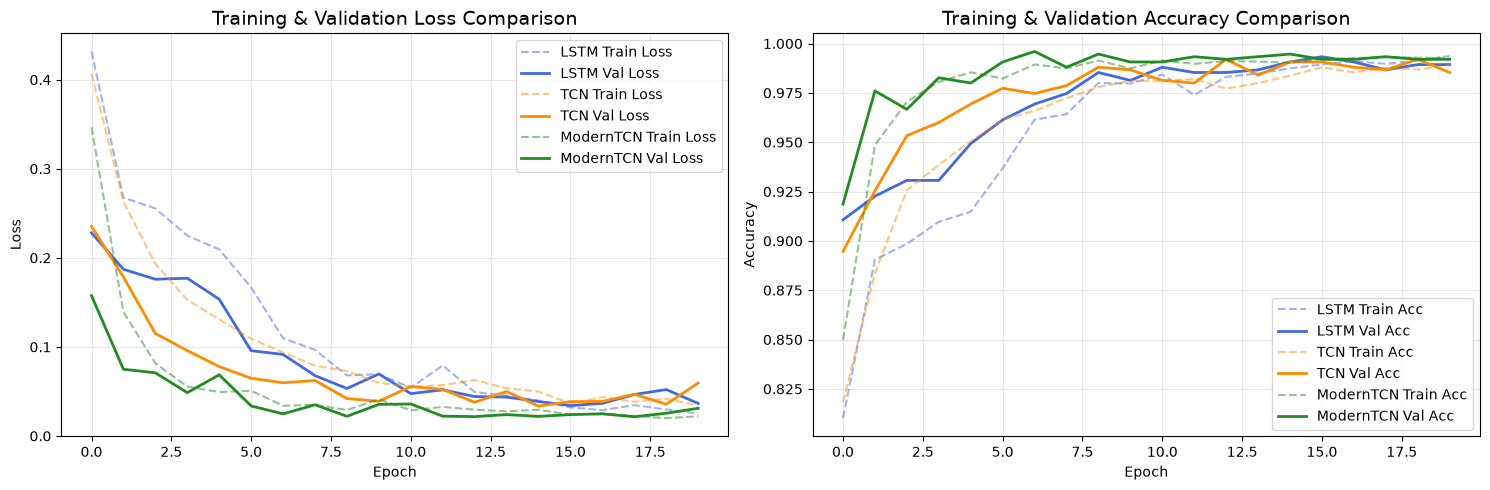

In [6]:
# 1. 모델별 Train / Validation 학습 곡선 비교 시각화
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = {'LSTM': 'royalblue', 'TCN': 'darkorange', 'ModernTCN': 'forestgreen'}

for name, hist in histories.items():
    axes[0].plot(hist['train_loss'], linestyle='--', alpha=0.5, color=colors[name], label=f'{name} Train Loss')
    axes[0].plot(hist['val_loss'], lw=2, color=colors[name], label=f'{name} Val Loss')

    axes[1].plot(hist['train_acc'], linestyle='--', alpha=0.5, color=colors[name], label=f'{name} Train Acc')
    axes[1].plot(hist['val_acc'], lw=2, color=colors[name], label=f'{name} Val Acc')

axes[0].set_title('Training & Validation Loss Comparison', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Training & Validation Accuracy Comparison', fontsize=14)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== 📊 [LSTM] Test Classification Report (Acc: 0.9827, F1: 0.9790, AUC: 0.9971) ===
              precision    recall  f1-score   support

  Normal (0)     0.9797    0.9909    0.9852       438
 Anomaly (1)     0.9870    0.9712    0.9790       312

    accuracy                         0.9827       750
   macro avg     0.9833    0.9810    0.9821       750
weighted avg     0.9827    0.9827    0.9826       750

=== 📊 [TCN] Test Classification Report (Acc: 0.9827, F1: 0.9790, AUC: 0.9954) ===
              precision    recall  f1-score   support

  Normal (0)     0.9797    0.9909    0.9852       438
 Anomaly (1)     0.9870    0.9712    0.9790       312

    accuracy                         0.9827       750
   macro avg     0.9833    0.9810    0.9821       750
weighted avg     0.9827    0.9827    0.9826       750

=== 📊 [ModernTCN] Test Classification Report (Acc: 0.9880, F1: 0.9856, AUC: 0.9970) ===
              precision    recall  f1-score   support

  Normal (0)     0.9886    0.9909    0

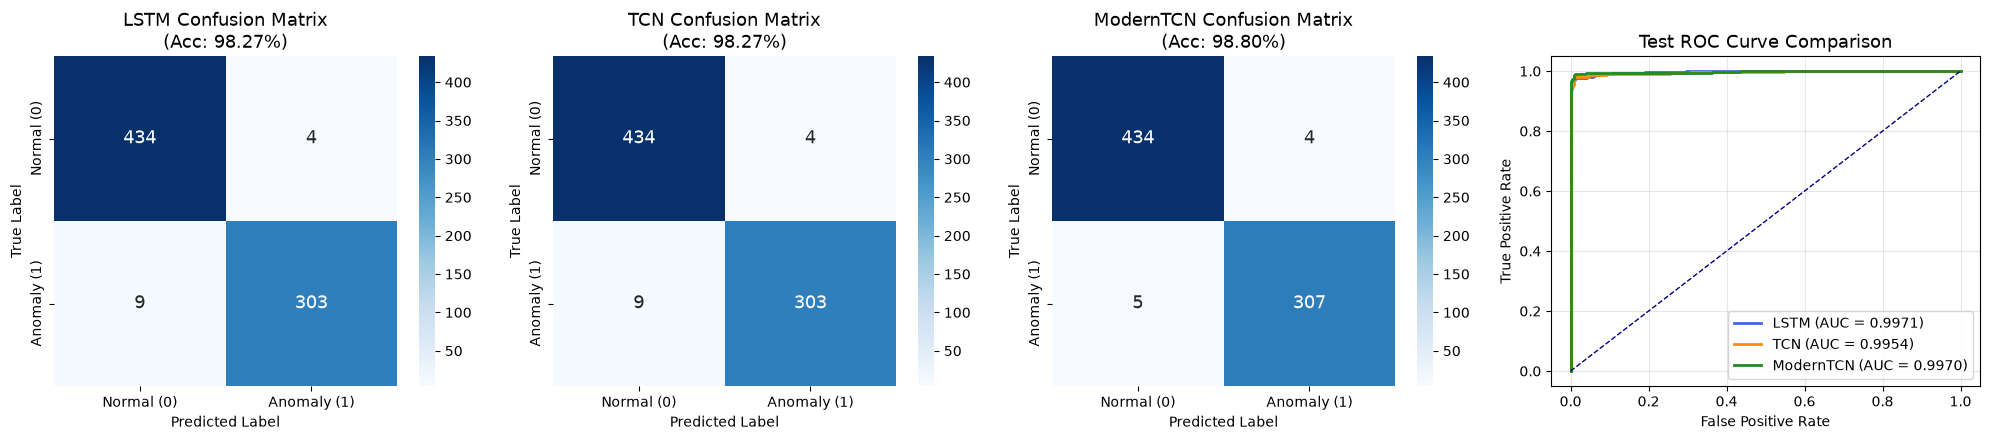

In [7]:
# 2. Test 데이터셋 평가, Confusion Matrix (3개 모델 나란히) 및 통합 ROC Curve 시각화
test_results = {}

for name, model in models.items():
    model.eval()
    preds_list, probs_list, targets_list = [], [], []
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            outputs = model(batch_x)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            preds = outputs.argmax(dim=1)

            preds_list.extend(preds.cpu().numpy())
            probs_list.extend(probs.cpu().numpy())
            targets_list.extend(batch_y.numpy())

    preds_arr = np.array(preds_list)
    probs_arr = np.array(probs_list)
    targets_arr = np.array(targets_list)

    fpr, tpr, _ = roc_curve(targets_arr, probs_arr)
    roc_auc = auc(fpr, tpr)
    acc = accuracy_score(targets_arr, preds_arr)
    f1 = f1_score(targets_arr, preds_arr)

    test_results[name] = {
        'preds': preds_arr, 'probs': probs_arr, 'targets': targets_arr,
        'cm': confusion_matrix(targets_arr, preds_arr),
        'fpr': fpr, 'tpr': tpr, 'auc': roc_auc, 'acc': acc, 'f1': f1
    }

    print(f'=== 📊 [{name}] Test Classification Report (Acc: {acc:.4f}, F1: {f1:.4f}, AUC: {roc_auc:.4f}) ===')
    print(classification_report(targets_arr, preds_arr, target_names=['Normal (0)', 'Anomaly (1)'], digits=4))

# Confusion Matrix 3개 + ROC Curve 1개 시각화
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for i, (name, res) in enumerate(test_results.items()):
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Normal (0)', 'Anomaly (1)'],
                yticklabels=['Normal (0)', 'Anomaly (1)'], annot_kws={'size': 13})
    axes[i].set_title(f'{name} Confusion Matrix\n(Acc: {res["acc"]:.2%})', fontsize=13)
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

# 통합 ROC Curve
for name, res in test_results.items():
    axes[3].plot(res['fpr'], res['tpr'], lw=2, color=colors[name],
                 label=f'{name} (AUC = {res["auc"]:.4f})')
axes[3].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
axes[3].set_title('Test ROC Curve Comparison', fontsize=13)
axes[3].set_xlabel('False Positive Rate')
axes[3].set_ylabel('True Positive Rate')
axes[3].legend(loc='lower right')
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

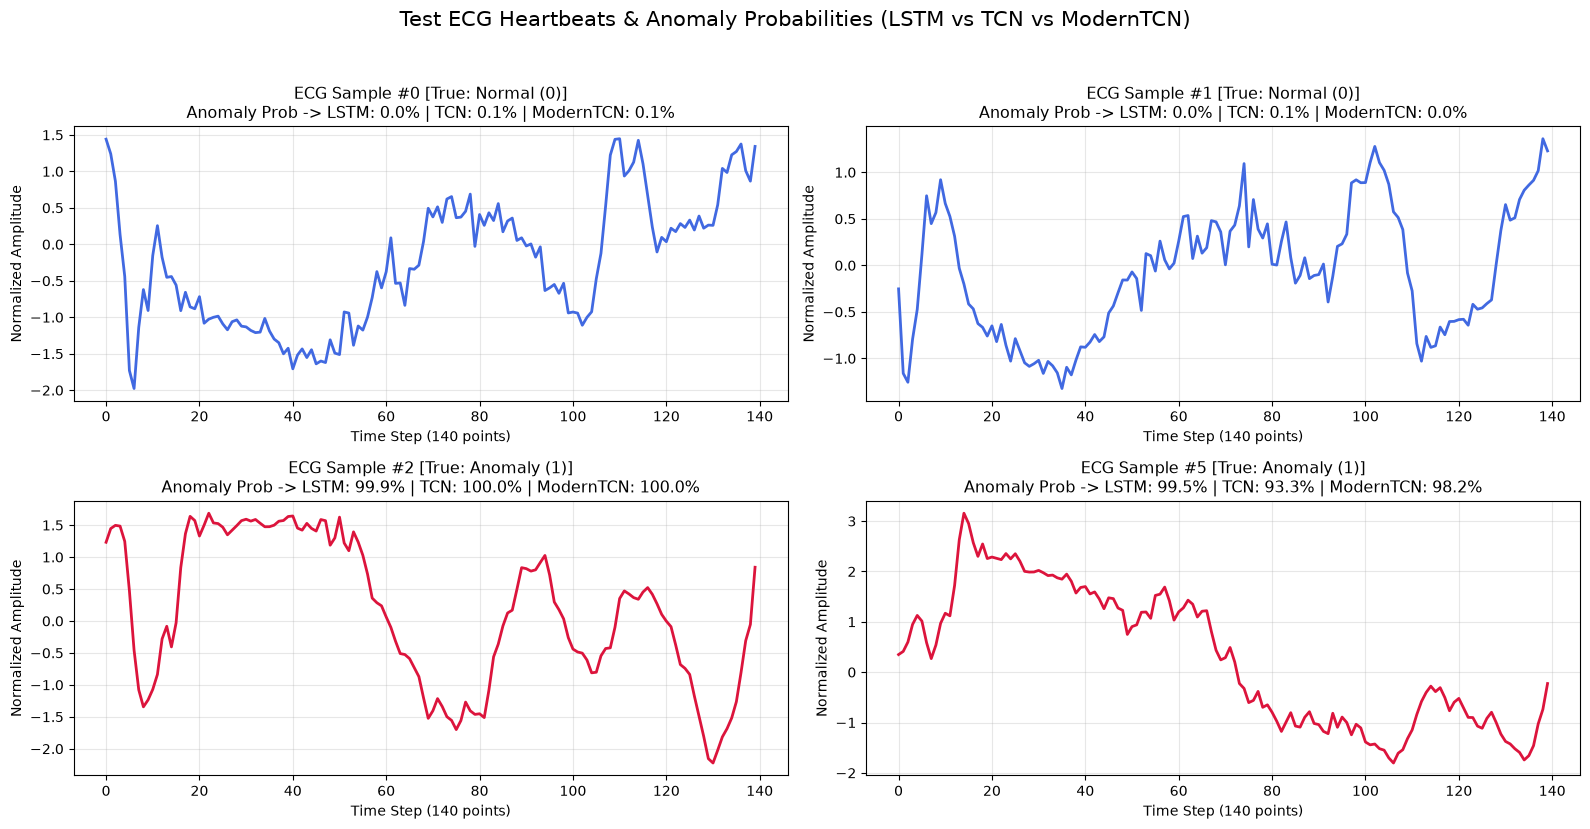

In [8]:
# 3. Test 샘플 심전도(ECG) 파형에 대한 3가지 모델의 예측 결과 비교 시각화
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()

targets_arr = test_results['LSTM']['targets']
test_normal_indices = np.where(targets_arr == 0)[0][:2]
test_anomaly_indices = np.where(targets_arr == 1)[0][:2]
sample_indices = np.concatenate([test_normal_indices, test_anomaly_indices])

for i, idx in enumerate(sample_indices):
    series = X_test[idx].squeeze()
    true_label_str = 'Anomaly (1)' if targets_arr[idx] == 1 else 'Normal (0)'
    line_color = 'crimson' if targets_arr[idx] == 1 else 'royalblue'

    # 각 모델의 이상(Anomaly) 예측 확률 추출
    pred_summary = ' | '.join([
        f'{name}: {res["probs"][idx]:.1%}' for name, res in test_results.items()
    ])

    axes[i].plot(series, color=line_color, lw=2)
    axes[i].set_title(
        f'ECG Sample #{idx} [True: {true_label_str}]\nAnomaly Prob -> {pred_summary}',
        fontsize=11.5
    )
    axes[i].set_xlabel('Time Step (140 points)')
    axes[i].set_ylabel('Normalized Amplitude')
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Test ECG Heartbeats & Anomaly Probabilities (LSTM vs TCN vs ModernTCN)', fontsize=15, y=1.03)
plt.tight_layout()
plt.show()